In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
from torch.utils.data import Dataset,DataLoader

In [8]:
import numpy as np

In [9]:
print(torch.cuda.is_available())

True


In [10]:
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
RANDOM_SEED=123
BACTH_SIZE=256
NUM_OF_EPOCHS=5

In [11]:
torch.random.manual_seed(RANDOM_SEED)

In [12]:
lr = 0.1
model =torch.nn.Linear(10,1)
optimizer = torch.optim.Adam(model.parameters(),lr=lr)

In [13]:
lambda1 = lambda epoch: 0.95
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer=optimizer,gamma=0.1,milestones=[0,2,4])


In [14]:
print(optimizer.state_dict())
for e in range(5):
    optimizer.step()
    scheduler.step()
    print(optimizer.state_dict()['param_groups'][0]['lr'])

{'state': {}, 'param_groups': [{'lr': 0.010000000000000002, 'betas': (0.9, 0.999), 'eps': 1e-08, 'weight_decay': 0, 'amsgrad': False, 'maximize': False, 'foreach': None, 'capturable': False, 'differentiable': False, 'fused': None, 'decoupled_weight_decay': False, 'initial_lr': 0.1, 'params': [0, 1]}]}
0.010000000000000002
0.0010000000000000002
0.0010000000000000002
0.00010000000000000003
0.00010000000000000003


In [15]:
resize_transfrom =torchvision.transforms.Compose(
    [
        torchvision.transforms.Resize((32,32)),
        torchvision.transforms.ToTensor(),
        torchvision.transforms.Normalize((0.5,),(0.5,))
    ]
)

In [16]:
train_dataset = torchvision.datasets.MNIST(
    root='./data',transform=resize_transfrom,train=True,download=True
)
test_dataset = torchvision.datasets.MNIST(
    root='./data',transform=resize_transfrom,train=False,download=True
)

In [17]:
train_dataloader = DataLoader(dataset=train_dataset,shuffle=True,num_workers=3,in_order=False,batch_size=int(len(train_dataset)/20))
test_dataloader = DataLoader(dataset=test_dataset,shuffle=True,num_workers=3,in_order=False,batch_size=int(len(test_dataset)/20))

In [ ]:
class LeNet5(torch.nn.Module):
    def __init__(self,num_classes,grayscale=False):
        super().__init__()
        self.grayscale = grayscale
        self.num_classes = num_classes
        in_channels = 1 if grayscale else 3 

        self.features = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels,6,kernel_size=5),
            torch.nn.Tanh(),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Conv2d(6,16,kernel_size=5),
            torch.nn.Tanh(),
            torch.nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = torch.nn.Sequential(
            torch.nn.Flatten(start_dim=1),
            torch.nn.Linear(16*5*5,120),
            torch.nn.Tanh(),
            torch.nn.Linear(120,84),
            torch.nn.Tanh(),
            torch.nn.Linear(84,num_classes)
        )
    def forward(self,X):
        return self.classifier(self.features(X))

    def train_model(self,data:DataLoader,lr=0.1,epochs=70,device='cuda:0'):
        error_margin = []
        loss_func = torch.nn.CrossEntropyLoss()
        optimizer = torch.optim.SGD(model.parameters(),lr=0.1,momentum=0.9)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,factor=0.1,mode='min')
        for e in range(epochs):
            print(e,end=',')
            for i,(X,y) in enumerate(data):
                X=X.to(device)
                y=y.to(device)
                prediction = self.forward(X)
                loss = loss_func(prediction,y)
                error_margin.append(loss.item())
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                scheduler.step(error_margin[-1])
        return error_margin
    def test_model(self, X, y):
    # Przełącz model w tryb ewaluacji (wyłącza np. Dropout)
        self.eval() 
        pointes_per_class = {}
        with torch.no_grad():
            # Pobierz logity z modelu
            outputs = self.forward(X)
            
            # Znajdź indeksy z najwyższym prawdopodobieństwem (dim=1 to wymiar klas)
            predictions = torch.argmax(outputs, dim=1)
            # Porównaj z prawdziwymi etykietami i policz trafienia
            correct = (predictions == y).sum().item()
            

            # Oblicz dokładność
            accuracy = correct / y.size(0)
            
            return accuracy





In [38]:
model = LeNet5(grayscale=True,num_classes=10)
model = model.to(DEVICE)



In [39]:
errors = model.train_model(train_dataloader)

0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,

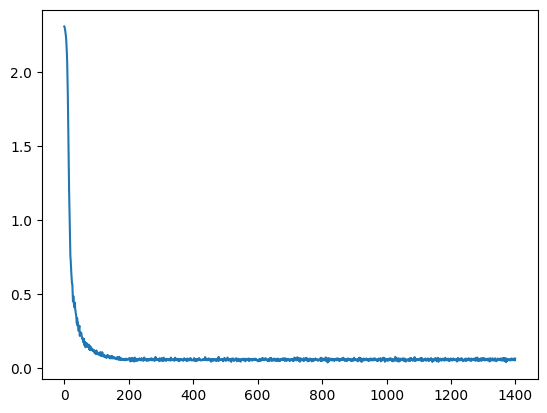

In [40]:
plt.plot(errors)

In [41]:
for i ,(x,y) in enumerate(test_dataloader):
    x=x.to(DEVICE)
    y=y.to(DEVICE)
    print(model.test_model(x,y))

0.988
0.982
0.982
0.98
0.984
0.994
0.984
0.972
0.988
0.986
0.986
0.976
0.97
0.98
0.984
0.986
0.98
0.974
0.982
0.984
